In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px

from pathlib import Path
from plotly.subplots import make_subplots

# -------------------------
# Dosya yolları
# -------------------------
DATA_DIR = Path("../data/out")

# CSV dosyaların Notebook ile aynı klasördeyse:
# DATA_DIR = Path(".")

# -------------------------
# Renk paleti
# -------------------------
COLORS = {
    "background": "#F3F4F6",
    "turkey": "#D32F2F",
    "others": "#D1D5DB",
    "asia": "#D55E00",
    "europe": "#0072B2",
    "africa": "#E69F00",
    "north_america": "#56B4E9",
    "south_america": "#009E73",
    "oceania": "#CC79A7",
    "projection": "#B58A50",
    "threshold": "#6B7280",
    "text": "#1F2937",
    "grid": "#D9DDE3",
}

# İkiz ülke grubundaki ülkeler
TWIN_COUNTRIES = {
    "SVN": {"name": "Slovenya", "color": COLORS["europe"]},
    "PRT": {"name": "Portekiz", "color": COLORS["europe"]},
    "ITA": {"name": "İtalya", "color": COLORS["europe"]},
    "DEU": {"name": "Almanya", "color": COLORS["europe"]},
    "GRC": {"name": "Yunanistan", "color": COLORS["europe"]},
    "JPN": {"name": "Japonya", "color": COLORS["asia"]},
}

# Türkiye ISO3 kodu
TURKEY_ISO3 = "TUR"

# -------------------------
# Ortak grafik teması
# -------------------------
BASE_LAYOUT = dict(
    template="plotly_white",
    paper_bgcolor=COLORS["background"],
    plot_bgcolor=COLORS["background"],
    font=dict(
        family="Arial, sans-serif",
        size=13,
        color=COLORS["text"],
    ),
    margin=dict(l=65, r=35, t=85, b=65),
    hoverlabel=dict(
        bgcolor="#FFFFFF",
        font_size=12,
        font_family="Arial, sans-serif",
    ),
    legend=dict(
        bgcolor="rgba(243,244,246,0.85)",
        borderwidth=0,
    ),
)

def apply_theme(fig, title, height=520):
    """Grafiklere ortak tema ve başlık uygular."""
    fig.update_layout(
        **BASE_LAYOUT,
        title=dict(
            text=title,
            x=0.02,
            xanchor="left",
        ),
        height=height,
    )
    fig.update_xaxes(
        showgrid=True,
        gridcolor=COLORS["grid"],
        zeroline=False,
    )
    fig.update_yaxes(
        showgrid=True,
        gridcolor=COLORS["grid"],
        zeroline=False,
    )
    return fig

In [2]:
path_mesafe = DATA_DIR / "g04_mesafe.csv"
path_yorunge = DATA_DIR / "g04_yorunge.csv"
path_zaman = DATA_DIR / "g04_zaman_makinesi.csv"

df_mesafe = pd.read_csv(path_mesafe)
df_yorunge = pd.read_csv(path_yorunge)
df_zaman = pd.read_csv(path_zaman)

print("g04_mesafe:", df_mesafe.shape)
print("g04_yorunge:", df_yorunge.shape)
print("g04_zaman_makinesi:", df_zaman.shape)

display(df_mesafe.head())
display(df_yorunge.head())
display(df_zaman.head())

g04_mesafe: (78, 4)
g04_yorunge: (1208, 7)
g04_zaman_makinesi: (48, 10)


,year,nearest_distance,threshold,has_twin
0,2023,0.043,0.149,True
1,2024,0.043,0.149,True
2,2025,0.040,0.149,True
3,2026,0.024,0.149,True
4,2027,0.029,0.149,True


,iso3,country,year,tfr,lex,median_age,is_projection
0,JPN,Japan,1950,3.6154,59.2548,21.3113,False
1,JPN,Japan,1951,3.2250,60.9885,21.4930,False
2,JPN,Japan,1952,2.9470,62.9959,21.7394,False
3,JPN,Japan,1953,2.6732,63.3252,22.0291,False
4,JPN,Japan,1954,2.4680,64.5367,22.3643,False


,query_year,rank,twin_iso3,twin_country,twin_year,distance,within_threshold,tfr,lex,median_age
0,2023,1,NLD,Netherlands,1987,0.043,True,1.5564,76.8133,32.4887
1,2023,2,IRN,Iran (Islamic Republic of),2022,0.052,True,1.7035,76.7993,32.3413
2,2023,3,CUB,Cuba,2001,0.061,True,1.5948,76.4287,32.6316
3,2028,1,CAN,Canada,1998,0.033,True,1.5525,78.6741,34.9550
4,2028,2,PRI,Puerto Rico,2008,0.057,True,1.6241,78.1105,35.0789


In [3]:
# Yıl ve sayısal sütunlar
numeric_columns = {
    "mesafe": ["year", "nearest_distance", "threshold"],
    "yorunge": ["year", "tfr", "lex", "median_age"],
    "zaman": [
        "query_year", "rank", "twin_year",
        "distance", "tfr", "lex", "median_age"
    ],
}

for col in numeric_columns["mesafe"]:
    df_mesafe[col] = pd.to_numeric(df_mesafe[col], errors="coerce")

for col in numeric_columns["yorunge"]:
    df_yorunge[col] = pd.to_numeric(df_yorunge[col], errors="coerce")

for col in numeric_columns["zaman"]:
    df_zaman[col] = pd.to_numeric(df_zaman[col], errors="coerce")


def to_bool(series):
    """CSV'den gelen True/False metinlerini güvenli biçimde dönüştürür."""
    return (
        series.astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": True,
            "false": False,
            "1": True,
            "0": False,
            "1.0": True,
            "0.0": False,
        })
        .astype("boolean")
    )


df_mesafe["has_twin"] = to_bool(df_mesafe["has_twin"])
df_yorunge["is_projection"] = to_bool(df_yorunge["is_projection"])
df_zaman["within_threshold"] = to_bool(df_zaman["within_threshold"])

# Metin sütunlarında boşlukları temizle
for df, cols in [
    (df_yorunge, ["iso3", "country"]),
    (df_zaman, ["twin_iso3", "twin_country"]),
]:
    for col in cols:
        df[col] = df[col].astype("string").str.strip()

# ISO3 kodlarını standartlaştır
df_yorunge["iso3"] = df_yorunge["iso3"].str.upper()
df_zaman["twin_iso3"] = df_zaman["twin_iso3"].str.upper()

print("Sütun tipleri hazır.")

Sütun tipleri hazır.


In [4]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path
import numpy as np
import pandas as pd

# -------------------------
# Output directory
# -------------------------
CHART_DIR = Path("../charts")
CHART_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------
# Export settings
# -------------------------
DPI = 300
FIGSIZE = (12, 7)

# -------------------------
# Color palette
# -------------------------
BACKGROUND = "#F3F4F6"

COLORS = {
    "background": BACKGROUND,
    "turkey": "#D32F2F",
    "others": "#D1D5DB",
    "asia": "#D55E00",
    "europe": "#0072B2",
    "africa": "#E69F00",
    "north_america": "#56B4E9",
    "south_america": "#009E73",
    "oceania": "#CC79A7",
    "cluster_1": "#2166AC",
    "cluster_2": "#67A9CF",
    "cluster_3": "#F7F7F7",
    "cluster_4": "#EF8A62",
    "cluster_5": "#B2182B",
    "projection": "#B58A50",
    "threshold": "#6B7280",
    "text": "#1F2937",
    "grid": "#D9DDE3",
}

# -------------------------
# Twin-country references
# -------------------------
TWIN_COUNTRIES = {
    "SVN": {"name": "Slovenia", "color": COLORS["europe"]},
    "PRT": {"name": "Portugal", "color": COLORS["europe"]},
    "ITA": {"name": "Italy", "color": COLORS["europe"]},
    "DEU": {"name": "Germany", "color": COLORS["europe"]},
    "GRC": {"name": "Greece", "color": COLORS["europe"]},
    "JPN": {"name": "Japan", "color": COLORS["asia"]},
}

TURKEY_ISO3 = "TUR"


def get_country_style(iso3):
    """Return the highlight color for a country."""
    iso3 = str(iso3).strip().upper()

    if iso3 == TURKEY_ISO3:
        return COLORS["turkey"]

    if iso3 in TWIN_COUNTRIES:
        return TWIN_COUNTRIES[iso3]["color"]

    return COLORS["others"]


def apply_matplotlib_theme(fig, axes, title):
    """Apply the shared visual theme to a Matplotlib figure."""
    fig.patch.set_facecolor(BACKGROUND)
    fig.suptitle(
        title,
        x=0.08,
        ha="left",
        fontsize=17,
        fontweight="bold",
        color=COLORS["text"],
    )

    if not isinstance(axes, (list, tuple, np.ndarray)):
        axes = [axes]

    for ax in np.asarray(axes, dtype=object).ravel():
        ax.set_facecolor(BACKGROUND)
        ax.tick_params(colors=COLORS["text"], labelsize=10)
        ax.xaxis.label.set_color(COLORS["text"])
        ax.yaxis.label.set_color(COLORS["text"])
        ax.grid(
            True,
            color=COLORS["grid"],
            linewidth=0.8,
            alpha=0.8,
        )
        ax.set_axisbelow(True)

        for spine in ax.spines.values():
            spine.set_visible(False)

    return fig


def save_chart(fig, filename):
    """Save a Matplotlib figure as a high-resolution PNG."""
    output_path = CHART_DIR / filename

    fig.savefig(
        output_path,
        dpi=DPI,
        bbox_inches="tight",
        facecolor=BACKGROUND,
    )

    print(f"Saved: {output_path.resolve()}")

Saved: C:\Users\Dell\Desktop\ASA-Dataquest-2026\charts\g04_similarity_distance.png


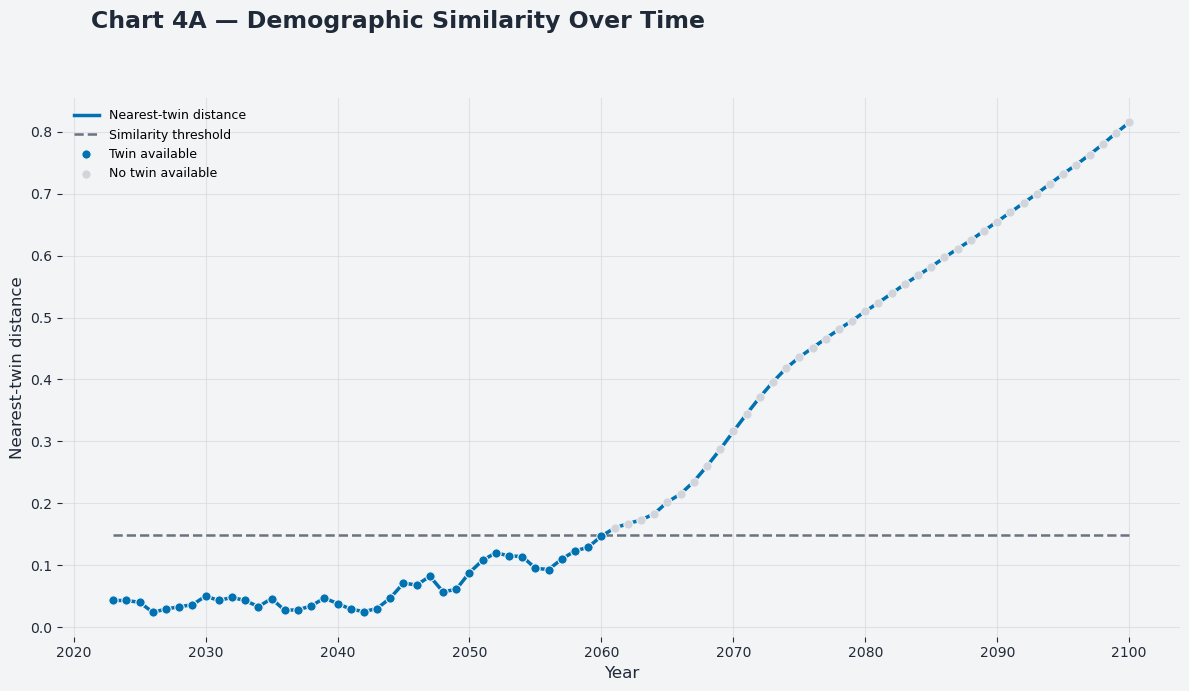

In [5]:
def plot_distance(df):
    """Plot nearest-twin distance and the similarity threshold."""
    data = df.sort_values("year").copy()

    fig, ax = plt.subplots(figsize=FIGSIZE)

    # Plot the nearest-twin distance
    ax.plot(
        data["year"],
        data["nearest_distance"],
        color=COLORS["europe"],
        linewidth=2.5,
        label="Nearest-twin distance",
        zorder=3,
    )

    # Plot the threshold, which may vary by year
    ax.plot(
        data["year"],
        data["threshold"],
        color=COLORS["threshold"],
        linewidth=1.8,
        linestyle="--",
        label="Similarity threshold",
        zorder=2,
    )

    # Highlight years with and without an available twin
    has_twin = (
        data["has_twin"]
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "1.0"])
    )

    for condition, label, color in [
        (has_twin, "Twin available", COLORS["europe"]),
        (~has_twin, "No twin available", COLORS["others"]),
    ]:
        subset = data.loc[condition]

        ax.scatter(
            subset["year"],
            subset["nearest_distance"],
            s=45,
            color=color,
            edgecolor=BACKGROUND,
            linewidth=0.8,
            label=label,
            zorder=4,
        )

    ax.set_xlabel("Year", fontsize=12)
    ax.set_ylabel("Nearest-twin distance", fontsize=12)

    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

    apply_matplotlib_theme(
        fig,
        ax,
        "Chart 4A — Demographic Similarity Over Time",
    )

    ax.legend(
        frameon=False,
        loc="best",
        fontsize=9,
    )

    fig.tight_layout(rect=[0, 0, 1, 0.93])

    save_chart(fig, "g04_similarity_distance.png")
    plt.show()

    return fig, ax


fig_distance, ax_distance = plot_distance(df_mesafe)

Saved: C:\Users\Dell\Desktop\ASA-Dataquest-2026\charts\g04_demographic_trajectory.png


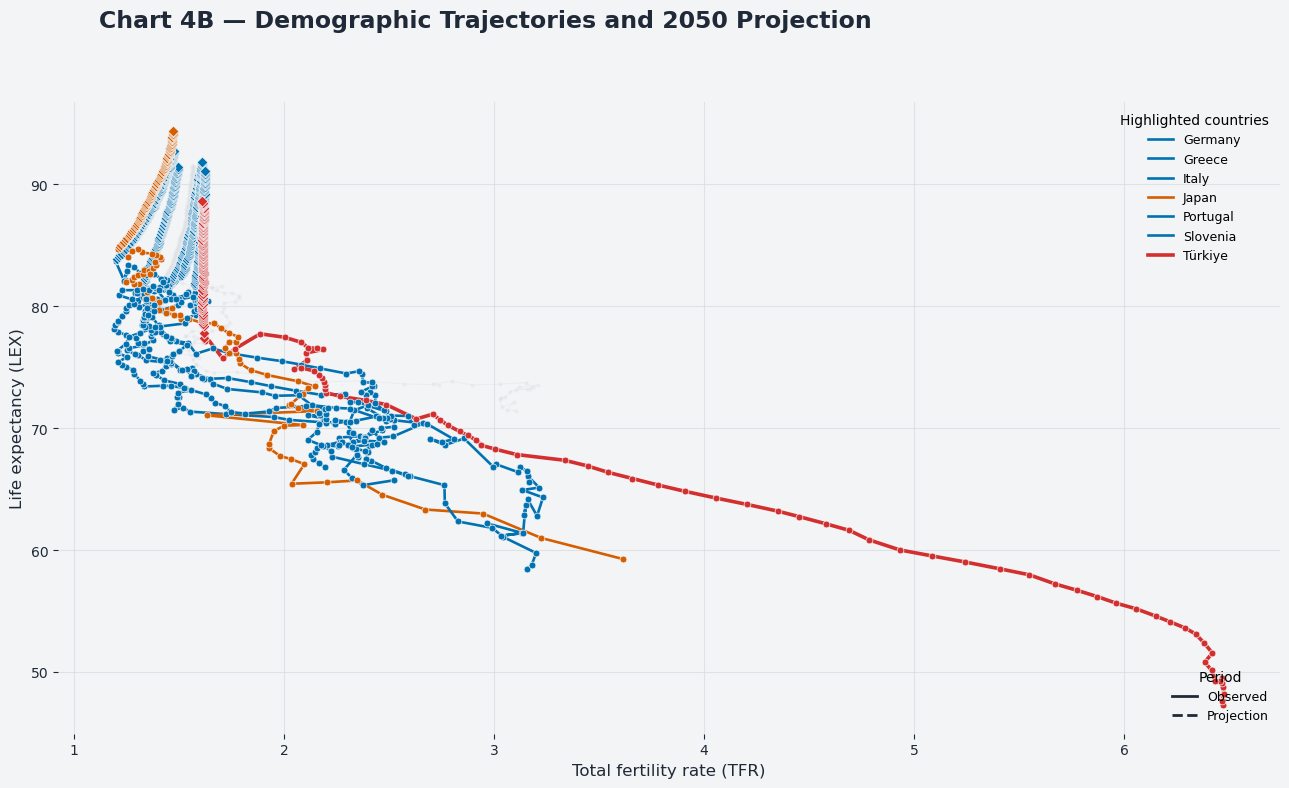

In [6]:
def plot_trajectory(df):
    """Plot fertility-life expectancy trajectories by country."""
    data = df.dropna(
        subset=[
            "iso3", "country", "year",
            "tfr", "lex", "is_projection"
        ]
    ).copy()

    data["iso3"] = data["iso3"].astype(str).str.upper()
    data = data.sort_values(["iso3", "year"])

    fig, ax = plt.subplots(figsize=(13, 8))

    # Plot each country separately
    for iso3, country_data in data.groupby("iso3", sort=False):
        country_data = country_data.sort_values("year")

        color = get_country_style(iso3)
        highlighted = (
            iso3 == TURKEY_ISO3 or iso3 in TWIN_COUNTRIES
        )

        observed = country_data.loc[
            ~country_data["is_projection"].astype(str).str.lower().isin(
                ["true", "1", "1.0"]
            )
        ]

        projected = country_data.loc[
            country_data["is_projection"].astype(str).str.lower().isin(
                ["true", "1", "1.0"]
            )
        ]

        # Use a single legend entry for each highlighted country
        if iso3 == TURKEY_ISO3:
            label = "Türkiye"
        elif iso3 in TWIN_COUNTRIES:
            label = TWIN_COUNTRIES[iso3]["name"]
        else:
            label = "_nolegend_"

        alpha = 1.0 if highlighted else 0.25
        line_width = 2.6 if iso3 == TURKEY_ISO3 else (
            1.9 if highlighted else 0.7
        )
        marker_size = 24 if highlighted else 9

        # Observed trajectory
        if not observed.empty:
            ax.plot(
                observed["tfr"],
                observed["lex"],
                color=color,
                linewidth=line_width,
                linestyle="-",
                alpha=alpha,
                label=label,
                zorder=4 if highlighted else 1,
            )

            ax.scatter(
                observed["tfr"],
                observed["lex"],
                s=marker_size,
                color=color,
                edgecolor=BACKGROUND,
                linewidth=0.5,
                alpha=alpha,
                zorder=5 if highlighted else 2,
            )

        # Projected trajectory
        if not projected.empty:
            projection_segment = projected.copy()

            # Include the last observed point to connect the projection
            if not observed.empty:
                projection_segment = pd.concat(
                    [observed.tail(1), projection_segment],
                    ignore_index=True,
                )

            ax.plot(
                projection_segment["tfr"],
                projection_segment["lex"],
                color=color,
                linewidth=line_width,
                linestyle="--",
                alpha=alpha,
                zorder=4 if highlighted else 1,
            )

            ax.scatter(
                projected["tfr"],
                projected["lex"],
                s=marker_size * 1.3,
                marker="D",
                color=color,
                edgecolor=BACKGROUND,
                linewidth=0.6,
                alpha=alpha,
                zorder=5 if highlighted else 2,
            )

    # Add a separate legend for line styles
    from matplotlib.lines import Line2D

    style_legend = [
        Line2D(
            [0], [0],
            color=COLORS["text"],
            linewidth=2,
            linestyle="-",
            label="Observed",
        ),
        Line2D(
            [0], [0],
            color=COLORS["text"],
            linewidth=2,
            linestyle="--",
            label="Projection",
        ),
    ]

    country_legend = ax.legend(
        frameon=False,
        loc="best",
        fontsize=9,
        title="Highlighted countries",
    )
    ax.add_artist(country_legend)

    ax.legend(
        handles=style_legend,
        frameon=False,
        loc="lower right",
        fontsize=9,
        title="Period",
    )

    ax.set_xlabel("Total fertility rate (TFR)", fontsize=12)
    ax.set_ylabel("Life expectancy (LEX)", fontsize=12)

    apply_matplotlib_theme(
        fig,
        ax,
        "Chart 4B — Demographic Trajectories and 2050 Projection",
    )

    fig.tight_layout(rect=[0, 0, 1, 0.93])

    save_chart(fig, "g04_demographic_trajectory.png")
    plt.show()

    return fig, ax


fig_trajectory, ax_trajectory = plot_trajectory(df_yorunge)

In [7]:
def plot_twin_profiles(df, query_year=2050):
    """Compare twin-country profiles for a selected query year."""
    data = df.loc[df["query_year"] == query_year].copy()

    data = data.dropna(
        subset=[
            "twin_country", "twin_year", "rank",
            "distance", "tfr", "lex", "median_age"
        ]
    ).sort_values("rank")

    if data.empty:
        raise ValueError(
            f"No twin profiles found for query year {query_year}."
        )

    fig, ax = plt.subplots(figsize=FIGSIZE)

    # Plot each twin-country profile
    for _, row in data.iterrows():
        iso3 = str(row["twin_iso3"]).upper()
        color = get_country_style(iso3)

        ax.scatter(
            row["tfr"],
            row["lex"],
            s=110,
            color=color,
            edgecolor="#FFFFFF",
            linewidth=1.2,
            zorder=3,
        )

        # Add the country label
        ax.annotate(
            str(row["twin_country"]),
            (row["tfr"], row["lex"]),
            xytext=(7, 7),
            textcoords="offset points",
            fontsize=9,
            color=COLORS["text"],
        )

    ax.set_xlabel("Total fertility rate (TFR)", fontsize=12)
    ax.set_ylabel("Life expectancy (LEX)", fontsize=12)

    apply_matplotlib_theme(
        fig,
        ax,
        f"Chart 4C — Twin-Country Profiles for {query_year}",
    )

    fig.tight_layout(rect=[0, 0, 1, 0.93])

    save_chart(
        fig,
        f"g04_twin_profiles_{query_year}.png",
    )
    plt.show()

    return fig, ax


fig_twins, ax_twins = plot_twin_profiles(
    df_zaman,
    query_year=2050,
)

ValueError: No twin profiles found for query year 2050.

In [8]:
def plot_twin_ranking(df, query_year=2050):
    """Plot twin-country distance rankings for a selected query year."""
    data = df.loc[df["query_year"] == query_year].copy()

    data = data.dropna(
        subset=["twin_country", "rank", "distance"]
    ).copy()

    if data.empty:
        raise ValueError(
            f"No twin rankings found for query year {query_year}."
        )

    data["within_threshold_bool"] = (
        data["within_threshold"]
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "1.0"])
    )

    data = data.sort_values("rank", ascending=False)

    bar_colors = [
        COLORS["europe"] if within else COLORS["others"]
        for within in data["within_threshold_bool"]
    ]

    fig, ax = plt.subplots(figsize=(11, 6))

    bars = ax.barh(
        data["twin_country"],
        data["distance"],
        color=bar_colors,
        edgecolor=BACKGROUND,
        linewidth=0.8,
        height=0.68,
    )

    # Annotate bars with their ranking
    max_distance = data["distance"].max()
    offset = max_distance * 0.015 if max_distance > 0 else 0.01

    for bar, (_, row) in zip(bars, data.iterrows()):
        ax.text(
            bar.get_width() + offset,
            bar.get_y() + bar.get_height() / 2,
            f"Rank {row['rank']:.0f}",
            va="center",
            ha="left",
            fontsize=9,
            color=COLORS["text"],
        )

    from matplotlib.patches import Patch

    legend_handles = [
        Patch(
            facecolor=COLORS["europe"],
            label="Within threshold",
        ),
        Patch(
            facecolor=COLORS["others"],
            label="Outside threshold",
        ),
    ]

    ax.legend(
        handles=legend_handles,
        frameon=False,
        loc="lower right",
        fontsize=9,
    )

    ax.set_xlabel("Calculated distance", fontsize=12)
    ax.set_ylabel("Twin country", fontsize=12)

    # Keep room for ranking labels at the end of each bar
    ax.set_xlim(
        left=0,
        right=max_distance * 1.25 if max_distance > 0 else 1,
    )

    apply_matplotlib_theme(
        fig,
        ax,
        f"Chart 4D — Twin-Country Distance Ranking for {query_year}",
    )

    fig.tight_layout(rect=[0, 0, 1, 0.93])

    save_chart(
        fig,
        f"g04_twin_ranking_{query_year}.png",
    )
    plt.show()

    return fig, ax


fig_ranking, ax_ranking = plot_twin_ranking(
    df_zaman,
    query_year=2050,
)

ValueError: No twin rankings found for query year 2050.

In [9]:
# Inspect available query years
print(
    sorted(
        df_zaman["query_year"]
        .dropna()
        .unique()
        .tolist()
    )
)

display(
    df_zaman.groupby("query_year", dropna=False)
    .agg(
        row_count=("twin_country", "size"),
        country_count=("twin_country", "nunique"),
        valid_distances=("distance", "count"),
    )
    .reset_index()
)

[2023, 2028, 2033, 2038, 2043, 2048, 2053, 2058, 2063, 2068, 2073, 2078, 2083, 2088, 2093, 2098]


,query_year,row_count,country_count,valid_distances
0,2023,3,3,3
1,2028,3,3,3
2,2033,3,3,3
3,2038,3,3,3
4,2043,3,3,3
5,2048,3,3,3
6,2053,3,3,3
7,2058,3,3,3
8,2063,3,3,3
9,2068,3,3,3


In [10]:
# Select the latest available query year
available_years = (
    pd.to_numeric(df_zaman["query_year"], errors="coerce")
    .dropna()
    .unique()
)

if len(available_years) == 0:
    raise ValueError("No valid query years found in df_zaman.")

QUERY_YEAR = int(max(available_years))

print(f"Selected query year: {QUERY_YEAR}")

Selected query year: 2098


Saved: C:\Users\Dell\Desktop\ASA-Dataquest-2026\charts\g04_twin_profiles_2098.png


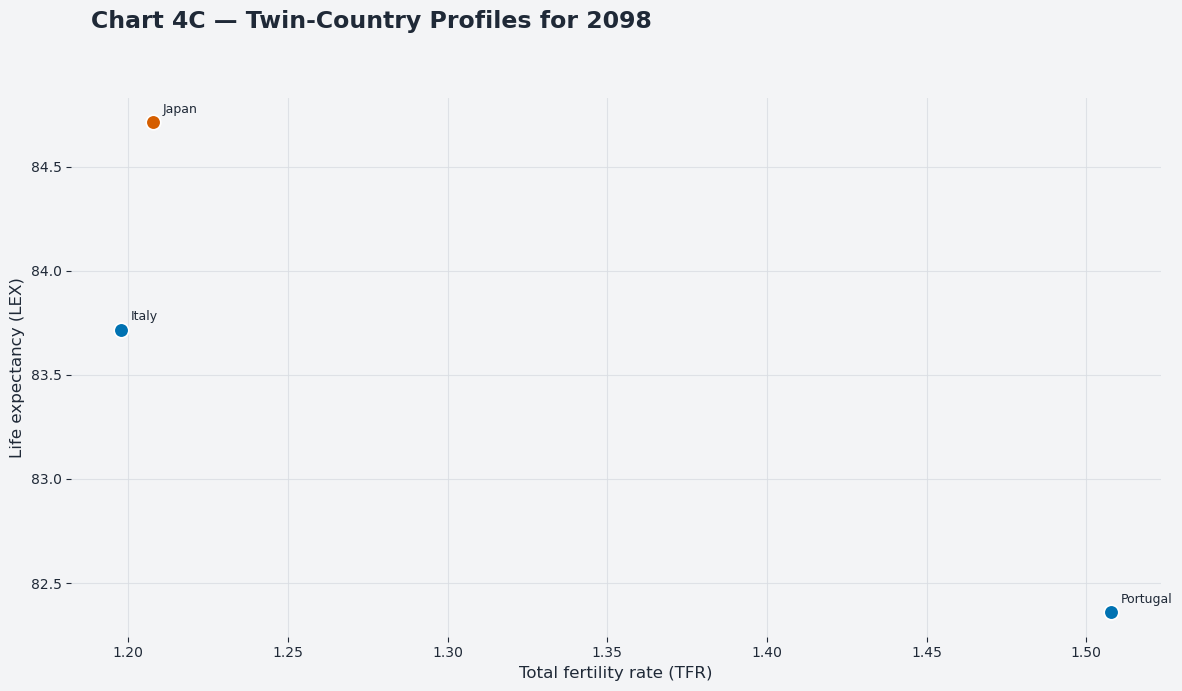

In [11]:
fig_twins, ax_twins = plot_twin_profiles(
    df_zaman,
    query_year=QUERY_YEAR,
)

Saved: C:\Users\Dell\Desktop\ASA-Dataquest-2026\charts\g04_twin_ranking_2098.png


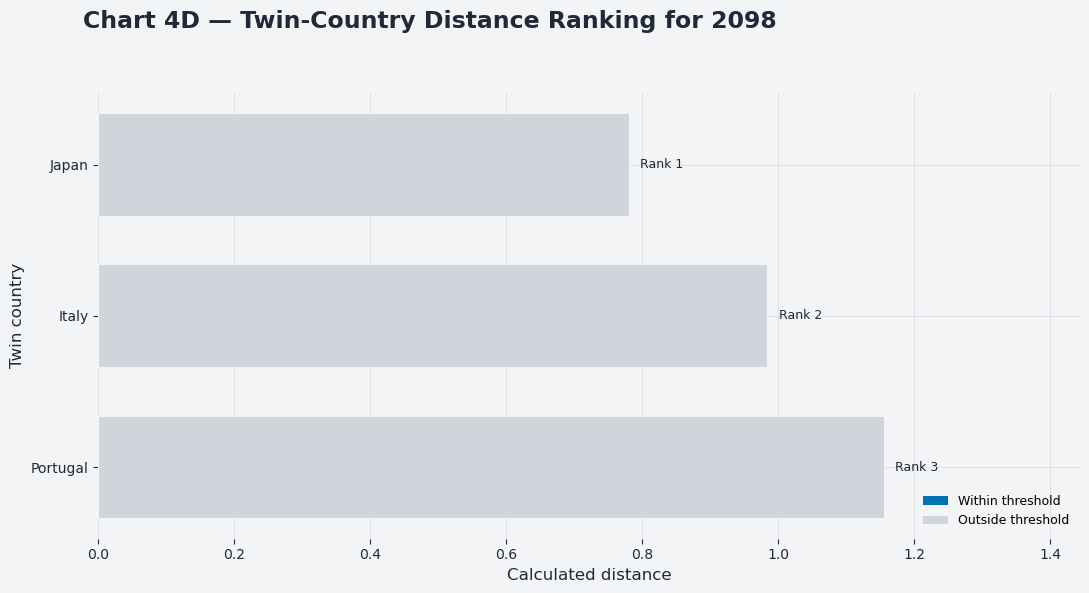

In [12]:
fig_ranking, ax_ranking = plot_twin_ranking(
    df_zaman,
    query_year=QUERY_YEAR,
)